# 1. Подготовка библиотек и параметров

In [1]:
import random
import time
from zipfile import ZipFile

import cv2
import numpy as np
import matplotlib.pyplot as plt

from skimage.feature import hog
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

random.seed(42)
np.random.seed(42)

IMAGE_SIZE = 64
SYMBOL_SIZE = 45
MAX_PER_CLASS = 500
K_VALUES = [1, 3, 5, 7, 9, 11]
SYMBOL_SPACING = 15
WORD_SPACING = 45

# 2. Загрузка набора данных

In [2]:
archive = ZipFile('data.zip')

def get_class_files():
    class_files = {}
    for path in archive.namelist():
        parts = path.replace('\\\\', '/').split('/')
        if len(parts) == 2 and parts[1].lower().endswith(('.jpg', '.jpeg', '.png')):
            label = parts[0]
            class_files.setdefault(label, []).append(path)
    return {label: sorted(paths) for label, paths in sorted(class_files.items())}


def read_image(path):
    data = np.frombuffer(archive.read(path), dtype=np.uint8)
    return cv2.imdecode(data, cv2.IMREAD_GRAYSCALE)


class_files = get_class_files()
name_folders = list(class_files.keys())

print('Классов:', len(name_folders))
print(name_folders)
print('Всего изображений:', sum(len(v) for v in class_files.values()))

Классов: 21
['(', ')', '+', ',', '-', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'X', 'h', 't', 'times', 'w', 'y']
Всего изображений: 225291


# 3. Подготовка изображений допустимых символов и преобразование в векторы признаков

In [3]:
def normalize_symbol(image, size=IMAGE_SIZE, padding=5):
    image = cv2.bitwise_not(image)
    _, mask = cv2.threshold(image, 15, 255, cv2.THRESH_BINARY)
    points = cv2.findNonZero(mask)

    result = np.zeros((size, size), dtype=np.uint8)
    if points is None:
        return result

    x, y, w, h = cv2.boundingRect(points)
    crop = image[y:y+h, x:x+w]

    target = size - 2 * padding
    scale = min(target / max(w, 1), target / max(h, 1))
    new_w = max(1, int(round(w * scale)))
    new_h = max(1, int(round(h * scale)))

    interpolation = cv2.INTER_AREA if scale < 1 else cv2.INTER_CUBIC
    crop = cv2.resize(crop, (new_w, new_h), interpolation=interpolation)

    x0 = (size - new_w) // 2
    y0 = (size - new_h) // 2
    result[y0:y0+new_h, x0:x0+new_w] = crop
    return result


def get_features(image):
    return hog(
        image,
        orientations=12,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm='L2-Hys',
        transform_sqrt=True
    ).astype(np.float32)


X_images = []
y = []
file_names = []

for label, files in class_files.items():
    files = files.copy()
    random.shuffle(files)
    for path in files[:MAX_PER_CLASS]:
        image = read_image(path)
        if image is None:
            continue
        X_images.append(normalize_symbol(image))
        y.append(label)
        file_names.append(path)

X_images = np.asarray(X_images, dtype=np.uint8)
y = np.asarray(y)
file_names = np.asarray(file_names)

X = np.asarray([get_features(image) for image in X_images], dtype=np.float32)

print('Изображений:', len(y))
print('Размер матрицы признаков:', X.shape)

Изображений: 10500
Размер матрицы признаков: (10500, 2352)


# 4. Проверка изображений символов из набора данных

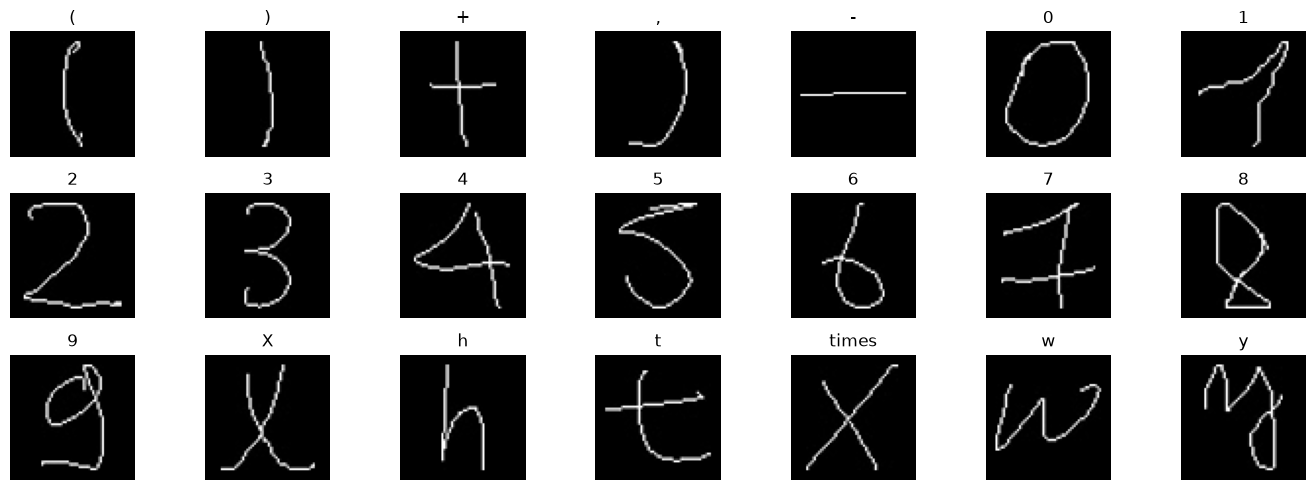

In [4]:
plt.figure(figsize=(14, 5))
for i, label in enumerate(name_folders):
    idx = np.where(y == label)[0][0]
    plt.subplot(3, 7, i + 1)
    plt.imshow(X_images[idx], cmap='gray')
    plt.title(label)
    plt.axis('off')
plt.tight_layout()
plt.show()

# 5. Разделение на обучающую и тестовую выборки

In [5]:
X_train, X_test, y_train, y_test, files_train, files_test = train_test_split(
    X, y, file_names,
    test_size=0.2,
    random_state=42,
    stratify=y
)

test_class_files = {
    label: files_test[y_test == label].tolist()
    for label in name_folders
}

print('Обучающая выборка:', X_train.shape)
print('Тестовая выборка:', X_test.shape)

Обучающая выборка: (8400, 2352)
Тестовая выборка: (2100, 2352)


# 6. Подбор оптимального значения k для классификатора KNN

k = 1 accuracy: 0.8923
k = 3 accuracy: 0.8976
k = 5 accuracy: 0.8875
k = 7 accuracy: 0.8893
k = 9 accuracy: 0.8875
k = 11 accuracy: 0.8863
Лучшее k: 3


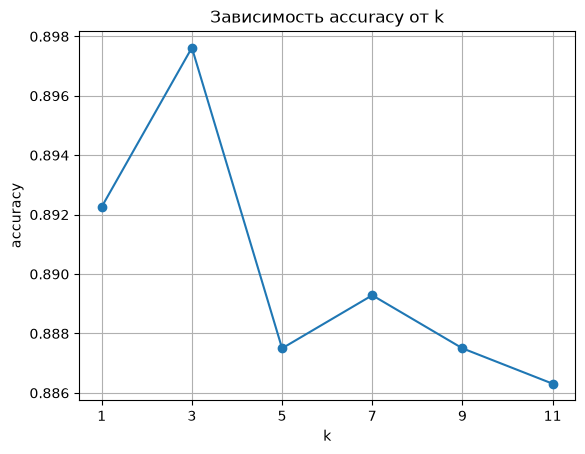

In [6]:
X_fit, X_valid, y_fit, y_valid, fit_files, valid_files = train_test_split(
    X_train, y_train, files_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

def augment_image(image):
    angle = random.uniform(-5, 5)
    shift_x = random.uniform(-2, 2)
    shift_y = random.uniform(-2, 2)
    scale = random.uniform(0.94, 1.06)

    matrix = cv2.getRotationMatrix2D((IMAGE_SIZE / 2, IMAGE_SIZE / 2), angle, scale)
    matrix[0, 2] += shift_x
    matrix[1, 2] += shift_y
    return cv2.warpAffine(
        image, matrix, (IMAGE_SIZE, IMAGE_SIZE),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=0
    )

path_to_image = {path: image for path, image in zip(file_names, X_images)}
X_fit_aug = [X_fit]
for _ in range(2):
    augmented = [
        get_features(augment_image(path_to_image[path]))
        for path in fit_files
    ]
    X_fit_aug.append(np.asarray(augmented, dtype=np.float32))

X_fit_aug = np.vstack(X_fit_aug)
y_fit_aug = np.tile(y_fit, 3)

accuracies = []
for k in K_VALUES:
    classifier = KNeighborsClassifier(
        n_neighbors=k, algorithm='brute', n_jobs=-1,
        weights='distance', metric='euclidean'
    )
    classifier.fit(X_fit_aug, y_fit_aug)
    prediction = classifier.predict(X_valid)
    acc = accuracy_score(y_valid, prediction)
    accuracies.append(acc)
    print('k =', k, 'accuracy:', round(acc, 4))

best_k = K_VALUES[int(np.argmax(accuracies))]
print('Лучшее k:', best_k)

plt.plot(K_VALUES, accuracies, 'o-')
plt.title('Зависимость accuracy от k')
plt.xlabel('k')
plt.ylabel('accuracy')
plt.xticks(K_VALUES)
plt.grid()
plt.show()

# 7. Финальная модель и оценка качества

In [7]:
best_classifier = KNeighborsClassifier(
    n_neighbors=best_k,
    algorithm='brute',
    n_jobs=-1,
    weights='distance',
    metric='euclidean'
)

path_to_image = {path: image for path, image in zip(file_names, X_images)}
X_train_aug = [X_train]
for _ in range(2):
    augmented = [
        get_features(augment_image(path_to_image[path]))
        for path in files_train
    ]
    X_train_aug.append(np.asarray(augmented, dtype=np.float32))

X_train_aug = np.vstack(X_train_aug)
y_train_aug = np.tile(y_train, 3)
best_classifier.fit(X_train_aug, y_train_aug)

y_pred_test = best_classifier.predict(X_test)
test_acc = accuracy_score(y_test, y_pred_test)

print('Оптимальное k:', best_k)
print('Accuracy на тестовой выборке:', round(test_acc, 4))
print(classification_report(y_test, y_pred_test, zero_division=0))

Оптимальное k: 3
Accuracy на тестовой выборке: 0.8967
              precision    recall  f1-score   support

           (       0.94      0.98      0.96       100
           )       0.85      0.93      0.89       100
           +       0.84      0.88      0.86       100
           ,       0.73      0.77      0.75       100
           -       0.95      1.00      0.98       100
           0       0.94      1.00      0.97       100
           1       0.80      0.75      0.77       100
           2       0.96      0.89      0.92       100
           3       0.95      0.88      0.91       100
           4       0.91      0.86      0.89       100
           5       0.95      0.95      0.95       100
           6       0.95      0.97      0.96       100
           7       0.92      0.91      0.91       100
           8       0.87      0.96      0.91       100
           9       0.87      0.89      0.88       100
           X       0.88      0.76      0.82       100
           h       0.91    

# 8. Генерация набора текстовых последовательностей

5w1 ,4+3 -> 7 символов
69 9* -> 4 символов
28 -> 2 символов
775X -> 4 символов
X46 -> 3 символов


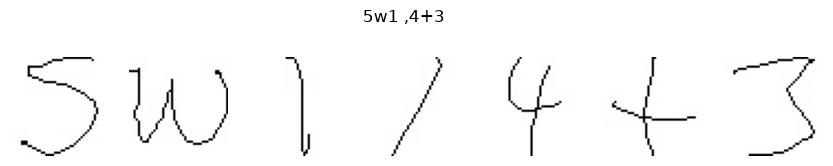

In [8]:
def load_random_symbol(label):
    path = random.choice(test_class_files[label])
    return read_image(path)


def generate_sequence(num_words=1, min_len=2, max_len=4, labels=None):
    if labels is None:
        labels = name_folders

    words = []
    images = []
    gaps = []

    for word_index in range(num_words):
        length = random.randint(min_len, max_len)
        word = [random.choice(labels) for _ in range(length)]
        words.append(word)

        for i, label in enumerate(word):
            images.append(load_random_symbol(label))
            if i < length - 1:
                gaps.append(SYMBOL_SPACING)

        if word_index < num_words - 1:
            gaps.append(WORD_SPACING)

    text = ' '.join(
        ''.join('*' if label == 'times' else label for label in word)
        for word in words
    )
    return text, images, gaps


def compose_sequence(images, gaps, margin=20):
    height = max(image.shape[0] for image in images)
    width = margin * 2 + sum(image.shape[1] for image in images) + sum(gaps)
    canvas = np.full((height + margin * 2, width), 255, dtype=np.uint8)

    x = margin
    for i, image in enumerate(images):
        y0 = margin + (height - image.shape[0]) // 2
        canvas[y0:y0+image.shape[0], x:x+image.shape[1]] = image
        x += image.shape[1]
        if i < len(gaps):
            x += gaps[i]

    return canvas


generated = [
    generate_sequence(num_words=random.randint(1, 2))
    for _ in range(5)
]

for text, images, gaps in generated:
    print(text, '->', len(images), 'символов')

first_text, first_images, first_gaps = generated[0]
plt.figure(figsize=(len(first_images) * 1.5, 2))
for i, image in enumerate(first_images):
    plt.subplot(1, len(first_images), i + 1)
    plt.imshow(image, cmap='gray')
    plt.axis('off')
plt.suptitle(first_text)
plt.show()

# 9. Формирование изображения последовательности

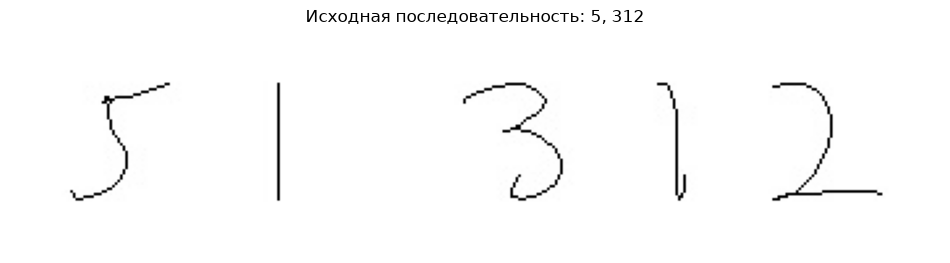

In [9]:
test_text, test_images, test_gaps = generate_sequence(
    num_words=2, min_len=2, max_len=4
)
test_image = compose_sequence(test_images, test_gaps)

plt.figure(figsize=(12, 3))
plt.imshow(test_image, cmap='gray')
plt.title('Исходная последовательность: ' + test_text)
plt.axis('off')
plt.show()

# 10. Выделение символов

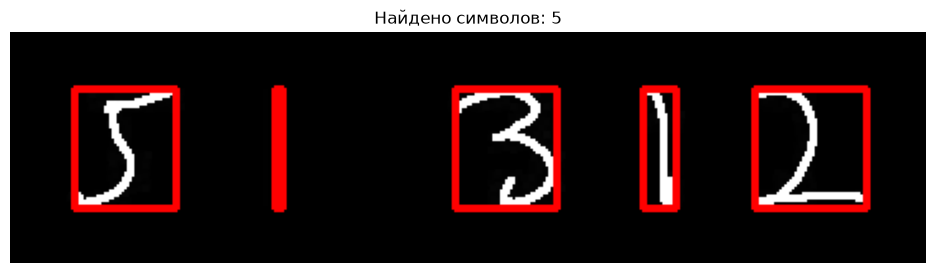

Количество выделенных символов: 5


In [10]:
def segment_symbols(image):
    img_gray = image.copy()
    source_gray = img_gray.copy()

    kernel = np.ones((3, 3), np.uint8)
    img_gray = cv2.erode(img_gray, kernel, iterations=1)
    img_gray = cv2.bitwise_not(img_gray)

    base = np.zeros((img_gray.shape[0] + 6, img_gray.shape[1] + 6), np.uint8)
    base[3:img_gray.shape[0]+3, 3:img_gray.shape[1]+3] = img_gray

    _, thresh = cv2.threshold(base, 127, 255, 0)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    boxes = []
    for contour in contours:
        x, y0, w, h = cv2.boundingRect(contour)
        if w * h > 50:
            boxes.append((x, y0, w, h))
    boxes = sorted(boxes, key=lambda box: box[0])

    data_img = []
    for x, y0, w, h in boxes:
        center_x = x - 3 + w // 2
        center_y = y0 - 3 + h // 2

        x1 = max(0, min(center_x - SYMBOL_SIZE // 2, source_gray.shape[1] - SYMBOL_SIZE))
        y1 = max(0, min(center_y - SYMBOL_SIZE // 2, source_gray.shape[0] - SYMBOL_SIZE))
        crop = source_gray[y1:y1+SYMBOL_SIZE, x1:x1+SYMBOL_SIZE]
        data_img.append((center_x, crop))

    vis = cv2.cvtColor(base, cv2.COLOR_GRAY2RGB)
    for x, y0, w, h in boxes:
        cv2.rectangle(vis, (x, y0), (x+w, y0+h), (255, 0, 0), 2)

    return vis, boxes, data_img


img_rgb, crops, data_img = segment_symbols(test_image)

plt.figure(figsize=(12, 3))
plt.imshow(img_rgb)
plt.title('Найдено символов: ' + str(len(crops)))
plt.axis('off')
plt.show()

print('Количество выделенных символов:', len(data_img))

# 11. Классификация символов и восстановление текста

In [11]:
def classify_symbols(data_img, model):
    predict_labels = []
    centers = []

    for center_x, image in data_img:
        normalized = normalize_symbol(image)
        features = get_features(normalized).reshape(1, -1)
        label = model.predict(features)[0]
        predict_labels.append(label)
        centers.append(center_x)

    return predict_labels, centers


predict_labels, centers = classify_symbols(data_img, best_classifier)

gaps = [
    centers[i+1] - centers[i]
    for i in range(len(centers)-1)
]
SPACE_GAP = SYMBOL_SIZE + (SYMBOL_SPACING + WORD_SPACING) // 2

result_text = ''
for i, label in enumerate(predict_labels):
    result_text += '*' if label == 'times' else label
    if i < len(gaps) and gaps[i] > SPACE_GAP:
        result_text += ' '

print('Исходный текст: ', test_text)
print('Распознанный текст:', result_text)

Исходный текст:  5, 312
Распознанный текст: 5, 3)2


# 12. Проверка нескольких последовательностей

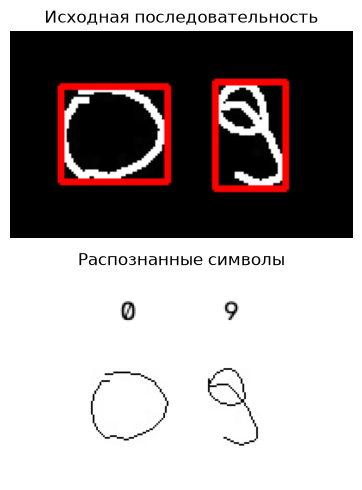

Исходный текст:  09
Распознанный текст: 09
Совпадение: True
---------------------------------------------


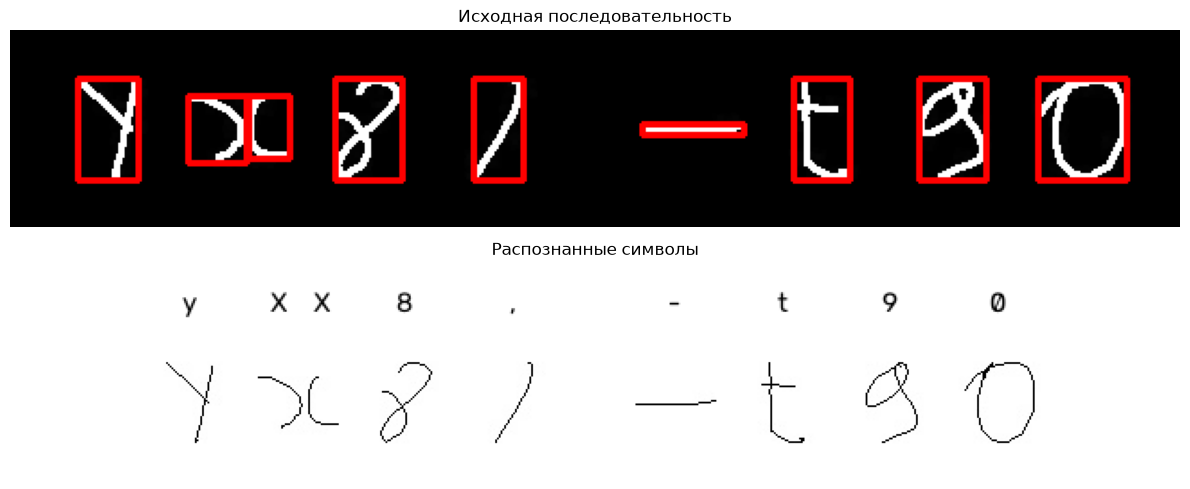

Исходный текст:  yX8) -t90
Распознанный текст: yXX8, -t90
Совпадение: False
---------------------------------------------


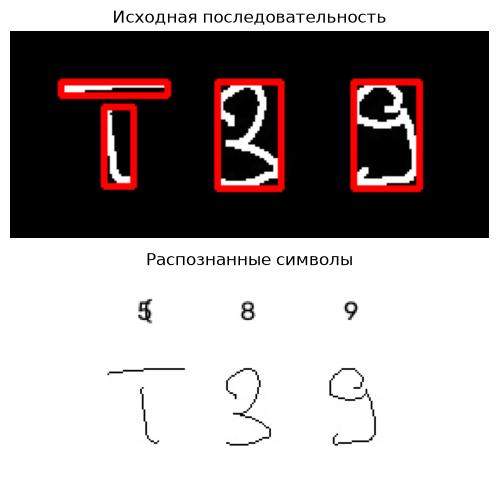

Исходный текст:  t39
Распознанный текст: 5(89
Совпадение: False
---------------------------------------------


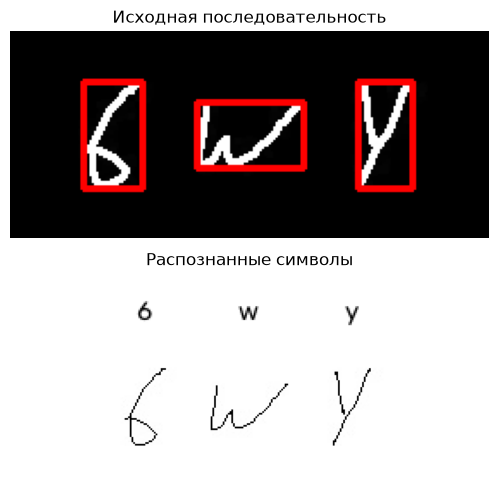

Исходный текст:  6wy
Распознанный текст: 6wy
Совпадение: True
---------------------------------------------


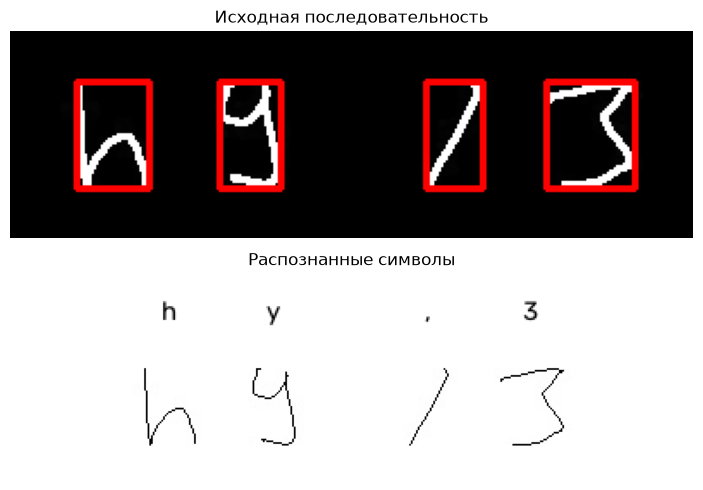

Исходный текст:  hy ,3
Распознанный текст: hy ,3
Совпадение: True
---------------------------------------------
Полностью совпавших строк: 3 из 5


In [12]:
def recognize_sequence(num_words=2):
    source_text, images, gaps = generate_sequence(
        num_words=num_words, min_len=2, max_len=4
    )
    image = compose_sequence(images, gaps)

    segmented_image, boxes, symbol_data = segment_symbols(image)
    labels, centers = classify_symbols(symbol_data, best_classifier)

    distances = [
        centers[i+1] - centers[i]
        for i in range(len(centers)-1)
    ]

    recognized = ''
    for i, label in enumerate(labels):
        symbol = '*' if label == 'times' else str(label)
        recognized += symbol
        if i < len(distances) and distances[i] > SPACE_GAP:
            recognized += ' '

    label_height = 35
    labeled_image = np.full(
        (image.shape[0] + label_height, image.shape[1]), 255, dtype=np.uint8
    )
    labeled_image[label_height:, :] = image

    for center_x, label in zip(centers, labels):
        symbol = '*' if label == 'times' else str(label)
        font = cv2.FONT_HERSHEY_SIMPLEX
        font_scale = 0.5
        thickness = 1
        (text_width, text_height), _ = cv2.getTextSize(
            symbol, font, font_scale, thickness
        )
        text_x = max(0, min(
            center_x - text_width // 2,
            labeled_image.shape[1] - text_width
        ))
        cv2.putText(
            labeled_image, symbol,
            (text_x, label_height - 8),
            font, font_scale, 0, thickness, cv2.LINE_AA
        )

    fig, axes = plt.subplots(2, 1, figsize=(12, 5))
    axes[0].imshow(segmented_image)
    axes[0].set_title('Исходная последовательность')
    axes[0].axis('off')

    axes[1].imshow(labeled_image, cmap='gray')
    axes[1].set_title('Распознанные символы')
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()

    print('Исходный текст: ', source_text)
    print('Распознанный текст:', recognized)
    print('Совпадение:', source_text == recognized)
    print('-' * 45)
    return source_text, recognized

results = [recognize_sequence(random.randint(1, 2)) for _ in range(5)]
correct = sum(source == result for source, result in results)
print('Полностью совпавших строк:', correct, 'из', len(results))

# Вывод
В работе реализованы генерация текстовых последовательностей из рукописных символов, их выделение и распознавание с помощью классификатора KNN.
Оптимальное значение параметра k выбрано с использованием метрики Accuracy. Распознанные символы объединяются в текст с восстановлением пробелов.